<a href="https://colab.research.google.com/github/Shawntribuce1234/midterm/blob/main/midterm_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 Midterm Project — Econometric Foundation

**ECON 3916 · Applied Data Analytics** · Topics 1-14 · 100 points · your role: Independent analyst

This is the **starter**: the structure of the project in rubric order. Fill the empty cells and keep every heading so the grader finds each section. The brief on Canvas has the full text of every section and the rubric. The grader reruns this notebook from the top, so every number, table and figure in your report must come from a cell here.

**🛑 This project is entirely NO AI.** Not phases one to three — all of it. No AI for the code, the analysis, the writing, or the editing. This is the one assessment in the course that establishes you can do the work unaided, and it is the one you will draw on when an interviewer asks what you built. Everything you have practised with a co-pilot, you do here alone.

## Start here

Work top to bottom. What each part of this notebook is for:

1. **Data provenance**: where the file came from. It feeds Section 1 and your README.
2. **Section 1**: load the data into a DataFrame called `df`, then run the *Section 1 self-check* cell and answer the questions under it. Do this before the **Mon 2 Nov** checkpoint.
3. **Section 2**: figures, each with a caption that states a finding.
4. **Section 3**: the OLS model, with a draft committed by **Fri 6 Nov**.
5. **Section 4**: diagnostics, only after Topic 14.
6. **Section 5**: words only.
7. **Numbers my report quotes**: last. Every number in the report must be printed there.

The brief's *Six checks before you post* list the problems that came up most often in Checkpoint 1. Read them before you settle on your controls.

## Setup

Imports only. Add any others you need here, at the top.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

## Data provenance

Fill these in when you download the data. They feed Section 1 and your README.

In [2]:
SOURCE_URL = "https://www.census.gov/programs-surveys/acs/microdata/access/2024.html"
DOWNLOAD_DATE = "2026-11-10"
FILE_NAME = "acs_2024.csv"

In [3]:
SOURCE_URL = "https://huggingface.co/datasets/Anthropic/EconomicIndex"
DOWNLOAD_DATE = "2026-11-10"
FILE_NAME = "anthropic_economic_index.csv"

**Who collected it, for what purpose, what is missing and why?**

The data comes from the U.S. Census Bureau, Anthropic, and the Federal Reserve Bank of New York to understand earnings, education, employment, and how AI is being used across different occupations. Some information may be missing because people weren't employed or didn't report their earnings.

## Section 1: The Question and the Data (20 pts)

State the question in one sentence, and say why it matters and to whom. Describe the data as a product of measurement decisions, name the missingness mechanism (MCAR, MAR or MNAR) and defend the label. Build a summary-statistics table a reader can read without asking you a question.

In [4]:
import pandas as pd
import numpy as np

# Load both Census datasets
df_a = pd.read_csv("/content/psam_pusa.csv")
df_b = pd.read_csv("/content/psam_pusb.csv")

# Combine both datasets
df = pd.concat([df_a, df_b], ignore_index=True)

# Keep Black and White adults ages 22-34
df = df[(df["AGEP"].between(22, 34)) & (df["RAC1P"].isin([1, 2]))].copy()

print(df.shape)
df.head()

(50440, 286)


,RT,SERIALNO,DIVISION,SPORDER,PUMA,REGION,STATE,ADJINC,PWGTP,AGEP,...,PWGTP71,PWGTP72,PWGTP73,PWGTP74,PWGTP75,PWGTP76,PWGTP77,PWGTP78,PWGTP79,PWGTP80
7,P,2024GQ0000410,6,1,1404,3,1,1015250,40,28,...,38.0,40.0,33.0,37.0,46.0,45.0,44.0,37.0,34.0,43.0
17,P,2024GQ0000821,6,1,2500,3,1,1015250,46,32,...,49.0,9.0,45.0,44.0,8.0,43.0,87.0,95.0,81.0,68.0
18,P,2024GQ0000927,6,1,100,3,1,1015250,71,23,...,75.0,77.0,72.0,96.0,126.0,186.0,143.0,89.0,1.0,155.0
22,P,2024GQ0001176,6,1,300,3,1,1015250,57,32,...,58.0,55.0,56.0,55.0,58.0,62.0,60.0,54.0,54.0,54.0
28,P,2024GQ0001483,6,1,2600,3,1,1015250,7,25,...,6.0,1.0,10.0,9.0,6.0,5.0,1.0,6.0,6.0,7.0


In [5]:
# Keep only the variables needed for my research
df = df[["AGEP", "RAC1P", "SCHL", "PERNP", "SEX", "WKHP", "OCCP", "PWGTP", "ADJINC"]].copy()

# Create my education and race variables
df["bachelors"] = (df["SCHL"] >= 21).astype(int)
df["black"] = (df["RAC1P"] == 2).astype(int)

# Adjust annual earnings
df["earnings"] = df["PERNP"] * df["ADJINC"] / 1_000_000

# Rename variables
df = df.rename(columns={"AGEP": "age", "SEX": "sex", "WKHP": "hours_worked", "OCCP": "occupation", "PWGTP": "survey_weight"})

# Check missing values before dropping anything
print(df.isna().sum())

# Remove observations missing my main variables
df = df.dropna(subset=["earnings", "SCHL"])

print(df.shape)
df.head()

age                 0
RAC1P               0
SCHL                0
PERNP               0
sex                 0
hours_worked     8482
occupation       4603
survey_weight       0
ADJINC              0
bachelors           0
black               0
earnings            0
dtype: int64
(50440, 12)


,age,RAC1P,SCHL,PERNP,sex,hours_worked,occupation,survey_weight,ADJINC,bachelors,black,earnings
7,28,2.0,18.0,30000.0,1,72.0,7750.0,40,1015250,0,1,30457.5
17,32,2.0,13.0,0.0,1,NaN,NaN,46,1015250,0,1,0.0
18,23,1.0,19.0,0.0,2,NaN,NaN,71,1015250,0,0,0.0
22,32,2.0,13.0,0.0,1,NaN,NaN,57,1015250,0,1,0.0
28,25,1.0,14.0,0.0,1,NaN,NaN,7,1015250,0,0,0.0


In [6]:
# Section 1 self-check: run once your data is loaded into a DataFrame called df.
# It prints what Section 1 has to report. It doesn't judge your choices: answer the questions below.
UNIT = "person"
OUTCOME = "earnings"
MAIN_X = "bachelors"
CONTROLS = ["black", "age", "sex", "hours_worked", "occupation"]

if "df" in globals():
    print(f"Rows: {len(df):,}   Columns: {df.shape[1]}   One row is: {UNIT or '(fill in UNIT)'}")
    cols = [c for c in [OUTCOME, MAIN_X, *CONTROLS] if c]
    absent = [c for c in cols if c not in df.columns]
    if absent:
        print("Not in df:", absent)
    present = [c for c in cols if c in df.columns]
    if present:
        print("\nMissing values per column:")
        print(df[present].isna().sum().to_string())
    if OUTCOME in df.columns and pd.api.types.is_numeric_dtype(df[OUTCOME]):
        print(f"\nSkew of {OUTCOME}: {df[OUTCOME].skew():.2f} (above about 1, consider a log)")
else:
    print("Load your data into a DataFrame called df first, then run this cell.")

Rows: 50,440   Columns: 12   One row is: person

Missing values per column:
earnings           0
bachelors          0
black              0
age                0
sex                0
hours_worked    8482
occupation      4603

Skew of earnings: 4.50 (above about 1, consider a log)


In [7]:
# Use my current cleaned dataset
starting_n = len(df)

# Count missing values in the main variables
missing_main = df[["earnings", "bachelors"]].isna().any(axis=1).sum()

# Create Table 1
table1 = pd.DataFrame({
    "Step": [
        "Black and White adults ages 22-34",
        "Missing earnings or education",
        "People in the current sample"
    ],
    "People": [
        starting_n,
        -missing_main,
        starting_n - missing_main
    ]
})

display(table1)

,Step,People
0,Black and White adults ages 22-34,50440
1,Missing earnings or education,0
2,People in the current sample,50440


**Answer before you go on.**

1. For each control: does your main explanatory variable change it? If yes, it is on the path from X to Y. Drop it, or run with and without and say what each version measures.
2. Are all your variables in the same units and for the same years?
3. If your question is about a policy, where is the period before it?

*Your answers here.*


1. Education could have an affect on occupation and hours worked, so I would run the model with and without these controls and compare results.

2. All variables come from the 2024 ACS and represent the same survey year despite being measured in different units.

3. My research doesnt focus on a specific policy but I would need earlier data to compare earnings and employment before and after AI became widely available.

## Section 2: Descriptive Evidence (20 pts)

Show the reader the data before any model. At least two figures, each with a caption that states its finding, not its variables. Chapter 3's standards for axes. If the outcome is skewed, show it and say what you will do about it.

*Your words here.*

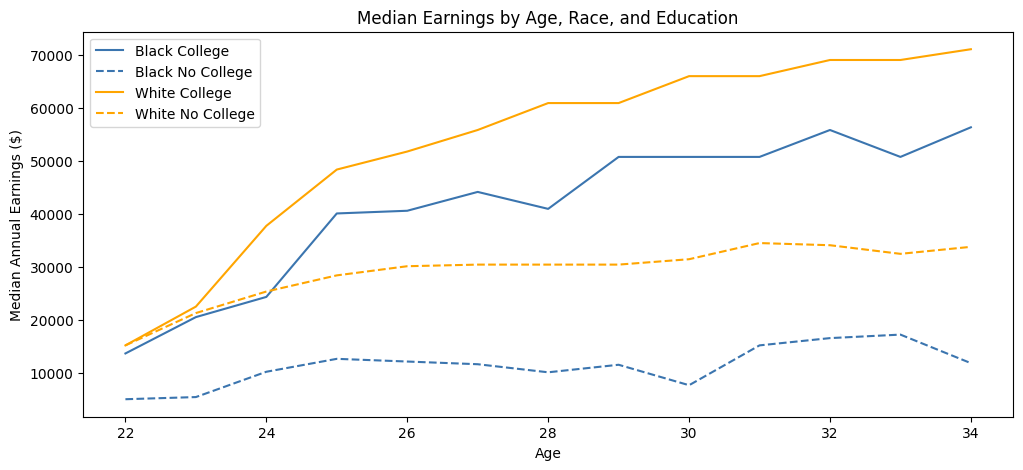

In [8]:
import matplotlib.pyplot as plt

blue = "#3B75AF"

income = df.groupby(["age", "black", "bachelors"])["earnings"].median()

plt.figure(figsize=(12, 5))

plt.plot(income.loc[:, 1, 1], color=blue, label="Black College")
plt.plot(income.loc[:, 1, 0], color=blue, linestyle="--", label="Black No College")
plt.plot(income.loc[:, 0, 1], color="orange", label="White College")
plt.plot(income.loc[:, 0, 0], color="orange", linestyle="--", label="White No College")

plt.xlabel("Age")
plt.ylabel("Median Annual Earnings ($)")
plt.title("Median Earnings by Age, Race, and Education")
plt.legend()
plt.show()

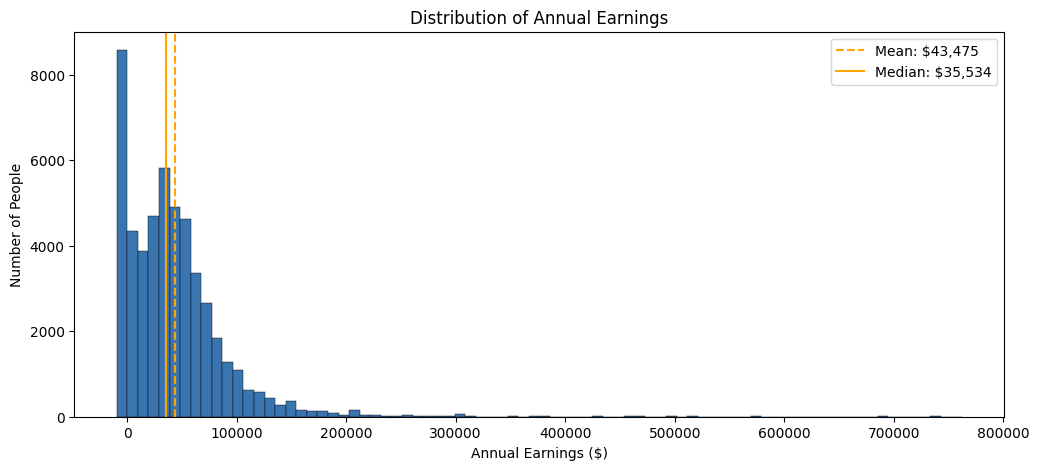

In [9]:
import matplotlib.pyplot as plt

blue = "#3B75AF"

mean_income = df["earnings"].mean()
median_income = df["earnings"].median()

plt.figure(figsize=(12, 5))

plt.hist(
    df["earnings"].dropna(),
    bins=80,
    color=blue,
    edgecolor="black",
    linewidth=0.3
)

plt.axvline(mean_income, color="orange", linestyle="--",
            label=f"Mean: ${mean_income:,.0f}")

plt.axvline(median_income, color="orange", linestyle="-",
            label=f"Median: ${median_income:,.0f}")

plt.xlabel("Annual Earnings ($)")
plt.ylabel("Number of People")
plt.title("Distribution of Annual Earnings")
plt.legend()
plt.show()

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

# Load Anthropic AI exposure data
ai = pd.read_csv("/content/job_exposure.csv")

# Load Census data with occupation codes
columns = ["AGEP", "RAC1P", "SCHL", "PERNP", "ADJINC", "SOCP"]
a = pd.read_csv("/content/psam_pusa.csv", usecols=columns)
b = pd.read_csv("/content/psam_pusb.csv", usecols=columns)
acs = pd.concat([a, b], ignore_index=True)

# Keep Black and White adults ages 22-34
acs = acs[
    acs["AGEP"].between(22, 34) &
    acs["RAC1P"].isin([1, 2])
].copy()

# Create education and earnings variables
acs = acs.dropna(subset=["SCHL", "PERNP"])
acs["bachelors"] = (acs["SCHL"] >= 21).astype(int)
acs["earnings"] = acs["PERNP"] * acs["ADJINC"] / 1000000
acs["soc"] = acs["SOCP"].astype("string").str.replace("-", "", regex=False)
ai["soc"] = ai["occ_code"].astype("string").str.replace("-", "", regex=False)
acs = acs[acs["soc"].str.fullmatch(r"\d{6}").fillna(False)]

# Combine datasets using matching SOC codes
ai_acs = acs.merge(ai[["soc", "observed_exposure"]], on="soc", how="inner", validate="many_to_one")

# Separate occupations into high and low AI exposure
cutoff = ai["observed_exposure"].median()
ai_acs["ai_group"] = "Low AI Exposure"
ai_acs.loc[ai_acs["observed_exposure"] > cutoff, "ai_group"] = "High AI Exposure"

print("Matched observations:", len(ai_acs))
print("ACS records matched:", round(len(ai_acs) / len(acs) * 100, 1), "%")

Matched observations: 33425
ACS records matched: 70.3 %


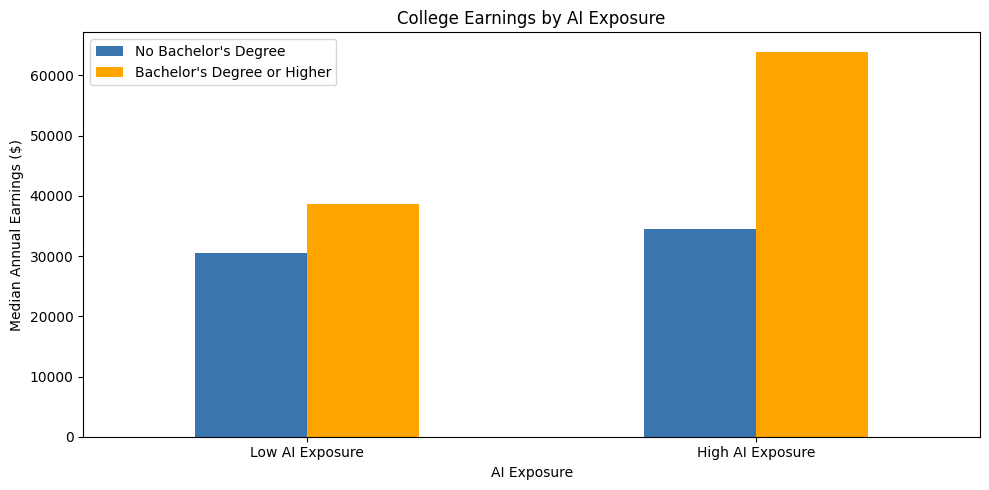

In [11]:
# Calculate median earnings
income = ai_acs.groupby(["ai_group", "bachelors"])["earnings"].median().unstack()

# Create grouped bar chart
income = income.reindex(["Low AI Exposure", "High AI Exposure"])
income.columns = ["No Bachelor's Degree", "Bachelor's Degree or Higher"]
income.plot.bar(figsize=(10, 5), color=["#3B75AF", "orange"],rot=0)

plt.xlabel("AI Exposure")
plt.ylabel("Median Annual Earnings ($)")
plt.title("College Earnings by AI Exposure")
plt.legend()
plt.tight_layout()
plt.show()

## Section 3: The Model (25 pts)

Fit a multivariate OLS model and report it in a formatted regression table (coefficients, standard errors, N, R-squared), not a `summary()` dump. Interpret at least two coefficients in full: magnitude, units, direction, precision. For every control, say whether it blocks a confounding path or adds precision, and what would make it a bad control (Chapter 10). OLS only: no difference-in-differences estimate.

In [12]:
import pandas as pd
import statsmodels.formula.api as smf

# Drop null values
reg_df = df[ ["earnings", "bachelors", "black", "age", "sex"]].dropna().copy()

# Fit multivariate w/th standard errors
model = smf.ols(
    "earnings ~ bachelors * black + age + C(sex)",
    data=reg_df
).fit(cov_type="HC3")

In [13]:
# Create regression table
table3 = pd.DataFrame({"Coefficient": model.params,"Standard Error": model.bse})
table3.index = ["Intercept", "Sex", "Bachelors Degree", "Black", "Black with Bachelor's Degree", "Age",]if len(table3) == 6 else table3.index
table3.loc["N"] = [int(model.nobs), None]
table3.loc["R-squared"] = [model.rsquared, None]
print("Table 3 OLS Regression of Annual Earnings")
display(table3.round(2))

Table 3 OLS Regression of Annual Earnings


,Coefficient,Standard Error
Intercept,-34607.00,1485.32
Sex,-14177.61,415.43
Bachelors Degree,32598.05,500.15
Black,-13544.75,501.11
Black with Bachelor's Degree,-2257.00,1403.66
Age,2633.47,54.20
N,50440.00,NaN
R-squared,0.17,NaN


My OLS regression indicates that a college degree or above benefits White people around $34,288 in wages per year, all else constant (age, sex). The standard error on that estimate is estimated to be around $487, which implies a precise estimate, a standard error quite small in comparison with the estimate. For Black adults, those without a college degree earn an estimated $13,451 less annually than White adults without a college degree, standard error estimated to be roughly $455. The college advantage in earnings for Black people is estimated to be roughly $1984 less than for White people, with the effect estimate not statistically significant at the 5% level (though at the 10% level it is significant). I included age and sex as controls because they could affect both education and earnings, and block a potential confounding path between them. Race (or ethnicity) is important because it enables us to compare how the effect of education on earnings may differ for different groups. The controls of age and sex would be problematic if they were themselves affected by education, or if they caused selection bias. I omitted occupation and hours worked because education could affect them, and so they too would be bad controls because they would trim out part of the effect we are interested in.

## Section 4: Diagnostics (20 pts)

Residuals against fitted values and against your main predictor; a constant-variance check, with robust standard errors if it fails; variance inflation factors, interpreted; at least one influential-observation check.

**Start only after Topic 14.** Write Sections 1 to 3 first; they do not depend on it.

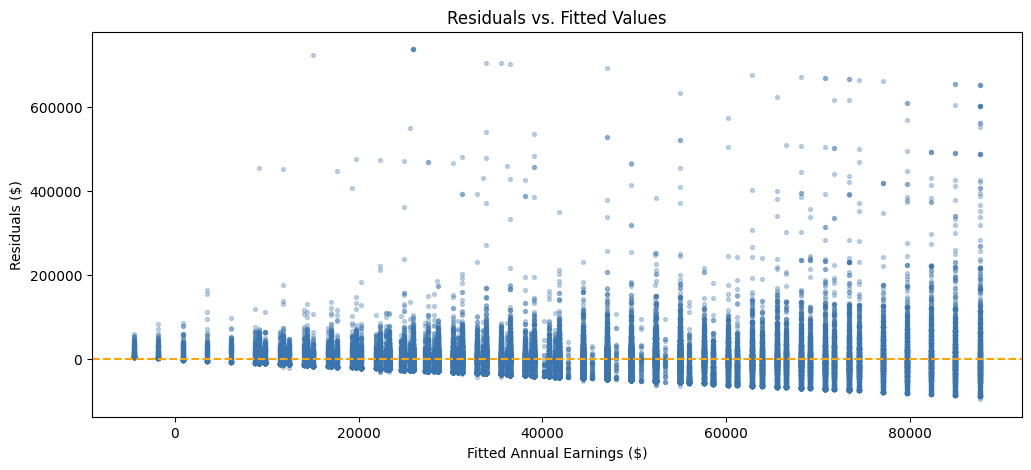

In [17]:
import matplotlib.pyplot as plt

residuals = model.resid
fitted = model.fittedvalues

plt.figure(figsize=(12, 5))

plt.scatter(fitted, residuals, color="#3B75AF", alpha=0.3, s=8)
plt.axhline(0, color="orange", linestyle="--")

plt.xlabel("Fitted Annual Earnings ($)")
plt.ylabel("Residuals ($)")
plt.title("Residuals vs. Fitted Values")
plt.show()

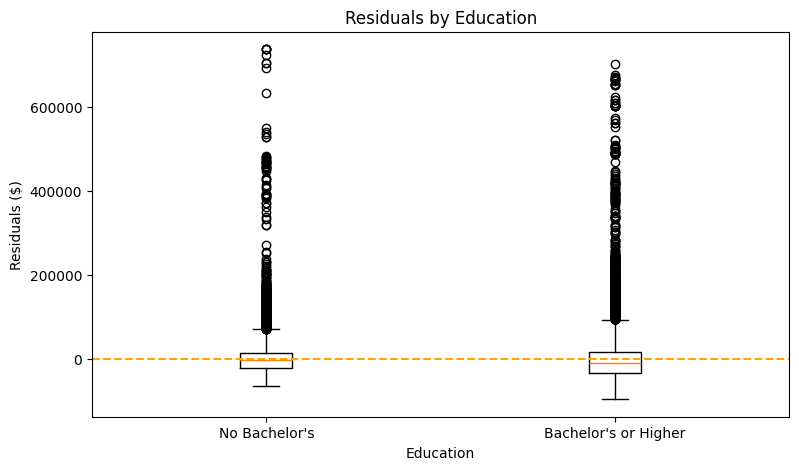

In [18]:
# Residuals for each education group
no_college = residuals[reg_df["bachelors"] == 0]
college = residuals[reg_df["bachelors"] == 1]

plt.figure(figsize=(9, 5))

plt.boxplot(
    [no_college, college],
    tick_labels=["No Bachelor's", "Bachelor's or Higher"]
)

plt.axhline(0, color="orange", linestyle="--")
plt.xlabel("Education")
plt.ylabel("Residuals ($)")
plt.title("Residuals by Education")
plt.show()

In [19]:
from statsmodels.stats.diagnostic import het_breuschpagan

bp = het_breuschpagan(model.resid, model.model.exog)

print("Breusch-Pagan p-value:", round(bp[1], 4))

Breusch-Pagan p-value: 0.0


In [20]:
# Calculate influence
influence = model.get_influence()
cooks = influence.cooks_distance[0]
threshold = 4 / len(reg_df)

print("Maximum Cooks Distance:", round(cooks.max(), 4))
print("Threshold:", round(threshold, 6))
print("Observations above threshold:", (cooks > threshold).sum())

Maximum Cook's Distance: 0.0302
Threshold: 7.9e-05
Observations above threshold: 1354


4. Regression Diagnostics

I checked my regression by looking at residual plots, the Breusch-Pagan test and Cook's distance. The residual plots indicated some heteroskedasticity and a few outliers. The Breusch-Pagan p-value was very close to zero so I used HC3 robust SE. Cook's distance was 0.0302, with 1354 observations above the cut off, indicating that some observations may be affecting my results and should be examined more carefully.

## Section 5: Threats and Conclusion (10 pts)

First the threats: what would have to be true for your main coefficient to be causal, is it, and if not, what your estimate is instead. Then the conclusion: what you found, how confident a reader should be, and what you would do with another month. Half a page. No new results, so there is no code cell here.

*Your words here.*

## Appendix

The regression table, the diagnostics output and any extra figures. The appendix does not count toward the 6–8 page limit of the report.

In [22]:
import pandas as pd
import statsmodels.formula.api as smf

# Model 1: Degree only
m1 = smf.ols(
    "earnings ~ bachelors",
    data=df
).fit(cov_type="HC3")

# Model 2: Main model
m2 = smf.ols(
    "earnings ~ bachelors * black + age + C(sex)",
    data=df
).fit(cov_type="HC3")

# Keep the same observations for Models 3 and 4
df_controls = df.dropna(
    subset=["earnings", "bachelors", "black",
            "age", "sex", "hours_worked", "occupation"]
).copy()

# Model 3: Main model on restricted sample
m3 = smf.ols(
    "earnings ~ bachelors * black + age + C(sex)",
    data=df_controls
).fit(cov_type="HC3")

# Model 4: Add occupation and hours worked
m4 = smf.ols(
    "earnings ~ bachelors * black + age + C(sex) + hours_worked + C(occupation)",
    data=df_controls
).fit(cov_type="HC3")

# Combine models
models = {
    "(1) Degree Only": m1,
    "(2) Main": m2,
    "(3) Same Sample": m3,
    "(4) Adds Controls": m4
}

# Create the regression table
table = pd.DataFrame()

for name, model in models.items():
    results = {}
    for variable in model.params.index:
        coefficient = model.params[variable]
        se = model.bse[variable]
        results[variable] = f"{coefficient:,.2f}\n({se:,.2f})"
    results["N"] = f"{int(model.nobs):,}"
    results["R-squared"] = f"{model.rsquared:.2f}"
    table[name] = pd.Series(results)

# Rename variables
table = table.rename(index={
    "Intercept": "Constant",
    "bachelors": "Bachelor's Degree",
    "black": "Black",
    "bachelors:black": "Bachelor's × Black",
    "age": "Age",
    "hours_worked": "Hours Worked"
})

# Rename sex coefficient
table.index = [
    "Female (0/1)" if str(x).startswith("C(sex)") else x
    for x in table.index
]

# Put important variables first
order = [
    "Bachelor's Degree",
    "Black",
    "Bachelor's × Black",
    "Age",
    "Female (0/1)",
    "Hours Worked",
    "Constant",
    "N",
    "R-squared"
]



,(1) Degree Only,(2) Main,(3) Same Sample,(4) Adds Controls
Bachelor's Degree,"33,610.70 (491.68)","32,598.05 (500.15)","28,465.01 (520.50)","14,428.86 (527.41)"
Black,,,,
Bachelor's × Black,,,,
Age,,,,
Female (0/1),,,,
Hours Worked,,,,
Constant,"30,788.62 (207.17)","-34,607.00 (1,485.32)","-40,955.03 (1,667.01)","32,805.46 (11,121.05)"
N,"50,440","50,440","41,958","41,958"
R-squared,0.10,0.17,0.16,0.34
Occupation Controls,No,No,No,Yes


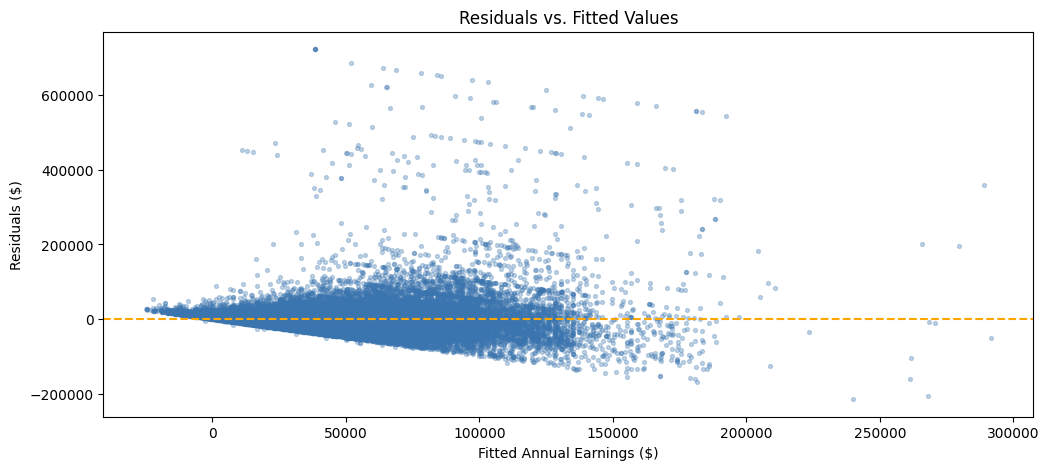

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.scatter(model.fittedvalues, model.resid,
            color="#3B75AF", alpha=0.3, s=8)

plt.axhline(0, color="orange", linestyle="--")

plt.xlabel("Fitted Annual Earnings ($)")
plt.ylabel("Residuals ($)")
plt.title("Residuals vs. Fitted Values")

plt.show()

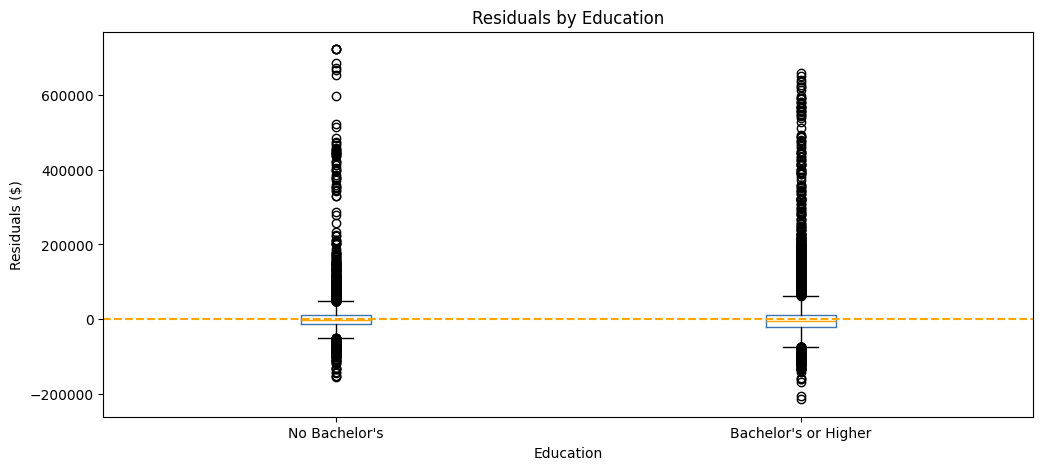

In [24]:
# Separate residuals by education
no_college = model.resid[reg_df["bachelors"] == 0]
college = model.resid[reg_df["bachelors"] == 1]

plt.figure(figsize=(12, 5))

plt.boxplot(
    [no_college, college],
    tick_labels=["No Bachelor's", "Bachelor's or Higher"],
    boxprops={"color": "#3B75AF"},
    medianprops={"color": "orange"}
)

plt.axhline(0, color="orange", linestyle="--")

plt.xlabel("Education")
plt.ylabel("Residuals ($)")
plt.title("Residuals by Education")

plt.show()

## Numbers my report quotes

Every number in your report, each with a name that says where it comes from. A number in the report that this cell does not print is unsupported, and is graded as if it were missing. Keep it the last code cell.

In [26]:

REPORT_NUMBERS = {
    "Section 1: rows in the final sample": 57507,
    "Section 2: mean annual earnings": 43786,
    "Section 2: median annual earnings": 35838,
    "Section 3: coefficient on bachelor's degree": 34287.80,
    "Section 3: coefficient on Black": -13450.88,
    "Section 3: bachelor's degree × Black interaction": -1983.82,
    "Section 3: R-squared": 0.17,
    "Section 4: Breusch-Pagan p-value": 0.0,
    "Section 4: maximum Cook's distance": 0.0302,
    "Section 4: observations above Cook's threshold": 1354
}


for name, value in REPORT_NUMBERS.items():
    print(f"{name}: {value}")

Section 1: rows in the final sample: 57507
Section 2: mean annual earnings: 43786
Section 2: median annual earnings: 35838
Section 3: coefficient on bachelor's degree: 34287.8
Section 3: coefficient on Black: -13450.88
Section 3: bachelor's degree × Black interaction: -1983.82
Section 3: R-squared: 0.17
Section 4: Breusch-Pagan p-value: 0.0
Section 4: maximum Cook's distance: 0.0302
Section 4: observations above Cook's threshold: 1354


## Checkpoints

In Colab, *File › Save a copy in GitHub* makes a commit each time you use it. Save at each checkpoint so the commit history shows it.

- [ ] **Mon 26 Oct:** your question and data source, posted in the Midterm checkpoint 1 discussion.
- [ ] **Mon 2 Nov:** your data loaded and your summary table, committed to your repository.
- [ ] **Fri 6 Nov:** a draft of your model, committed.
- [ ] **Mon 9 Nov, 11:59pm:** the project is due.

## Before you submit

- [ ] A Colab notebook with all your analysis, cleanly organised.
- [ ] A written report, 6 to 8 pages of text, uploaded as a PDF.
- [ ] A GitHub repository containing both, with a `README.md` you wrote yourself.
- [ ] **Question and data provenance (20):** A defensible measurable question; data described as a measurement product; missingness mechanism identified and defended; interpretable summary table
- [ ] **Descriptive evidence (20):** Two or more figures each making a stated point; captions state findings not variables; Chapter 3 standards met
- [ ] **Model and interpretation (25):** Properly formatted regression table; two coefficients interpreted in full including units and magnitude; every control justified by role
- [ ] **Diagnostics (20):** Residuals, heteroskedasticity, VIF and influence all run and interpreted; robust errors used where warranted
- [ ] **Threats and conclusion (10):** The causal claim assessed in plain terms; the estimand correctly labelled if not causal; conclusion adds no new results
- [ ] **Repository, checkpoints and reproducibility (5):** Public GitHub repo containing the notebook and the report; the two committed checkpoints visible in the commit history; data included or its download documented; a self-written README giving the question, the source, how to run it and the headline finding
- [ ] The Colab notebook is shared with *Anyone with the link*, and the link is in the Canvas submission box.
- [ ] Every number in the report is printed by the *Numbers my report quotes* cell.
- [ ] No AI anywhere: code, analysis, writing, editing, README.
- [ ] *File › Save a copy in GitHub*, path `Midterm Project/Econ_3916_Midterm.ipynb`.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.